# Diffusion Limited Aggregation — Parts II and III
EPS 109, Lab 6. Builds on the working Part I code in `DLA.ipynb`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

The Part I loop is wrapped in a function so the same code runs Parts II and III.
* `pLeft`, `pRight`: probability of a step left / right (up and down stay at 25% each).
* `p`: sticking probability. Part I corresponds to `pLeft = pRight = 0.25`, `p = 1`.

In [2]:
def run_dla(nParticles=10000, maxX=500, maxY=250, pLeft=0.25, pRight=0.25, p=1.0):
    A = np.zeros((maxX, maxY))
    A[:,0] = 1                      # sticky wall at the bottom
    yBuffer = 5
    yStart  = 1 + yBuffer

    for i in range(0, nParticles):
        x = np.random.randint(0, maxX)
        y = yStart

        while True:
            xOrg = x
            yOrg = y

            r = np.random.random()
            if r < pLeft:                         # left
                x = x - 1
            elif r < pLeft + pRight:              # right
                x = x + 1
            elif r < pLeft + pRight + 0.25:       # up
                y = y + 1
            else:                                 # down
                y = y - 1

            # periodic boundary conditions in x
            if x == -1:
                x = maxX - 1
            if x == maxX:
                x = 0

            if (A[x,y] == 1 or y > yStart):
                x = xOrg
                y = yOrg
                continue

            xp = x + 1
            xm = x - 1
            yp = y + 1
            ym = y - 1
            if xm == -1:
                xm = maxX - 1
            if xp == maxX:
                xp = 0

            neighbor_is_filled = False
            if A[xp,y] == 1 or A[xm,y] == 1 or A[x,yp] == 1 or A[x,ym] == 1:
                neighbor_is_filled = True

            if neighbor_is_filled:
                # Part III: only stick with probability p, otherwise keep diffusing
                if np.random.random() < p:
                    A[x,y] = 1
                    if (y+yBuffer > yStart and y+yBuffer < maxY):
                        yStart = y + yBuffer
                    break

        if (yStart+1 == maxY):
            print(f'Structures reached Y limit after only {i} particles')
            break

    return A

def show(A, title, nRows=None):
    if nRows is None:
        nRows = A.shape[1]
    plt.figure(figsize=(10, 10*nRows/A.shape[0] + 0.5))
    plt.imshow(A[:, :nRows].T, origin='lower', interpolation='nearest')
    plt.title(title)
    plt.axis('off')
    plt.show()

def height(A):
    return np.max(np.nonzero(A.any(axis=0))[0])

## Part II: flow to the right
Right 40%, left 10%, up 25%, down 25%. `maxX = 500`, `maxY = 250` (the Part I values from section 6).

Structures reached Y limit after only 4132 particles


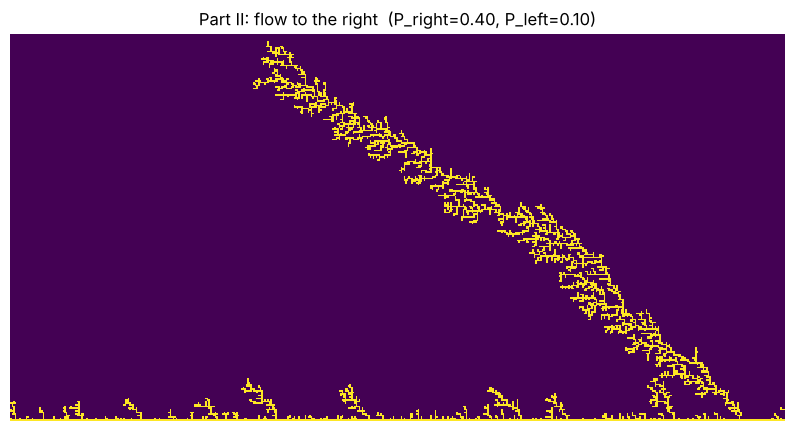

In [3]:
np.random.seed(1)
A2 = run_dla(nParticles=10000, maxX=500, maxY=250, pLeft=0.10, pRight=0.40)
show(A2, 'Part II: flow to the right  (P_right=0.40, P_left=0.10)')
plt.imsave('part2_flow.png', A2.T, origin='lower')

### Interpretation
The dendrites grow **against the stream** (like stalagmites): the branches lean to the **left**, upstream into the flow, rather than trailing downstream.

Why: particles drift to the right, so they mostly approach the aggregate from the left. The left (upstream) face of each branch catches almost all incoming particles, and the right (downstream) face sits in a "shadow" that few particles reach. Each new particle attaches on the upstream side, so the tip keeps moving upstream and up, and the branches tilt into the flow. The same screening that makes DLA branchy becomes directional with drift: one tree that leans upstream shadows everything downstream of it. As a result a single tilted tree wins quickly, and it grows much faster in height than in Part I. With `maxY = 250` the structure hits the top of the box after only about 4,100 particles, well short of 10,000.  Because of the periodic boundary in x, the tilted tree leaves the left edge and reappears on the right.

## Part III: sticking probability p
A particle touching the aggregate only sticks with probability `p`; otherwise it keeps diffusing. Same box as Part I (500 × 250), 10,000 particles.

p =   1.0:  height = 161 rows,  filling fraction = 0.12


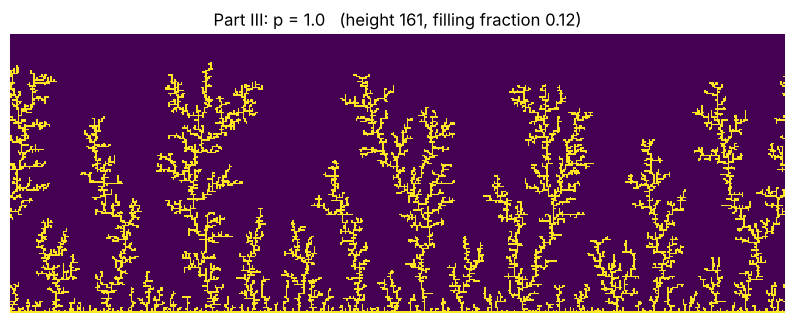

p =   0.3:  height = 127 rows,  filling fraction = 0.16


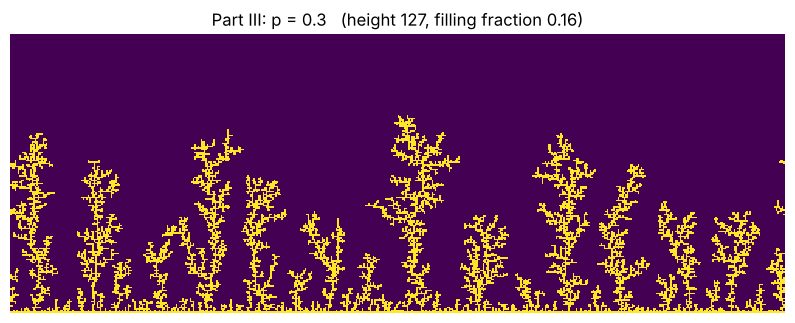

p =   0.1:  height =  98 rows,  filling fraction = 0.20


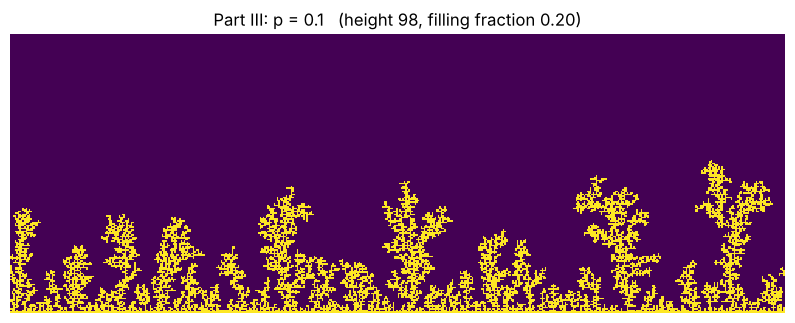

p =  0.03:  height =  50 rows,  filling fraction = 0.40


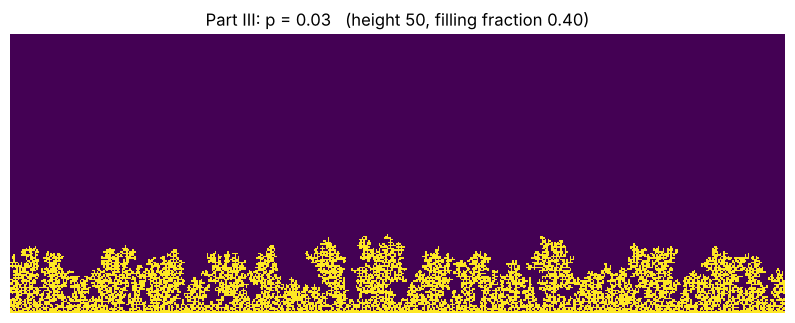

p =  0.01:  height =  44 rows,  filling fraction = 0.45


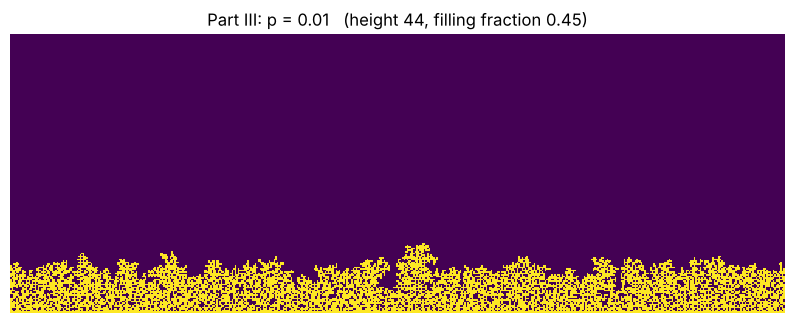

In [4]:
pValues = [1.0, 0.3, 0.1, 0.03, 0.01]
results = {}
for p in pValues:
    np.random.seed(1)
    A3 = run_dla(nParticles=10000, maxX=500, maxY=250, p=p)
    results[p] = A3
    h = height(A3)
    density = A3[:,1:].sum() / (A3.shape[0]*h)
    print(f'p = {p:5}:  height = {h:3d} rows,  filling fraction = {density:.2f}')
    show(A3, f'Part III: p = {p}   (height {h}, filling fraction {density:.2f})', nRows=180)
    plt.imsave(f'part3_p{p}.png', A3[:, :180].T, origin='lower')

### Interpretation
Lowering `p` makes the deposit steadily more compact:

| p | height (rows) | filling fraction |
|---|---|---|
| 1.0 | 161 | 0.12 |
| 0.3 | 127 | 0.16 |
| 0.1 | 98 | 0.20 |
| 0.03 | 50 | 0.40 |
| 0.01 | 44 | 0.45 |

(Exact numbers change a bit with the random seed.)

With `p = 1`, a particle sticks the first time it touches the aggregate, so it almost always lands on a branch tip. The tips screen the gaps between branches, and the result is the sparse, branchy DLA forest from Part I. With small `p`, a particle usually touches the surface many times before it sticks. It can roll off the tips and diffuse down into the gaps and fjords, so the screening effect is much weaker. The gaps fill in and the structure becomes dense with a fairly flat, rough surface. That is the compact picture on the right of the lab handout. In the limit `p → 0` you approach a compact (Eden-like) deposit. The cost is run time: each particle takes many more steps before it attaches.